# Degradation-Aware Prostate Grading

## Section 1: Setup



*   Imports
*   Mount Drive
*   Define BASE path
*   Verify folder structure



### 1.1 Imports

In [35]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential, layers

In [20]:
AUTOTUNE = tf.data.AUTOTUNE

### 1.2 Mount Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.3 Base Path & Structure Verification

In [3]:
BASE = '/content/drive/MyDrive/SICAPv2'

for item in os.listdir(BASE):
  print(item)

readme.txt
wsi_labels.xlsx
masks
images
partition


In [4]:
for item in os.listdir(f"{BASE}/partition"):
  print(item)

Validation
Test
manifest_train.csv
manifest_val.csv


In [5]:
for split in ['Test', 'Validation']:
    print(f'{split}:')
    for item in os.listdir(f'{BASE}/partition/{split}'):
        print(f'  {item}')

Test:
  Test.xlsx
  TestCribfriform.xlsx
  Train.xlsx
  TrainCribfriform.xlsx
Validation:
  Val2
  Val4
  Val3
  Val1


## Section 2: Data Exploration

* Load Train.xlsx and Test.xlsx
* Extract patiend IDs
* Check patient overlap between train and test
* Class distribution across train and test
* Sample a few images visually per class

### 2.1 Load Partition Files

In [6]:
df_train = pd.read_excel(f'{BASE}/partition/Test/Train.xlsx')
print("Shape:", df_train.shape)
print("Columns:", df_train.columns.tolist())
print()
print(df_train.head(3))

Shape: (9959, 6)
Columns: ['image_name', 'NC', 'G3', 'G4', 'G5', 'G4C']

                                          image_name  NC  G3  G4  G5  G4C
0  16B0001851_Block_Region_1_0_0_xini_6803_yini_5...   0   0   0   1    0
1  16B0001851_Block_Region_1_0_1_xini_7827_yini_5...   0   0   0   1    0
2  16B0001851_Block_Region_1_0_2_xini_8851_yini_5...   0   0   0   1    0


In [7]:
df_test = pd.read_excel(f'{BASE}/partition/Test/Test.xlsx')
print("Shape:", df_test.shape)
print("Columns:", df_test.columns.to_list())
print()
print(df_test.head(3))

Shape: (2122, 6)
Columns: ['image_name', 'NC', 'G3', 'G4', 'G5', 'G4C']

                                          image_name  NC  G3  G4  G5  G4C
0  16B0003388_Block_Region_13_10_1_xini_8636_yini...   0   0   1   0    0
1  16B0003388_Block_Region_13_10_2_xini_9660_yini...   0   0   1   0    0
2  16B0003388_Block_Region_13_10_3_xini_10684_yin...   0   0   1   0    0


### 2.2 Extract Patient IDs

**Purpose**

SICAPv2 ships with the train/test split already done. Those splits live in Excel files, so we load them into dataframes. Then we pull a patient ID from each image filename -- something like "16B0001851_..." -- where everything before the first underscore identifies the patient. That ID is what the overlap check in the next cell runs on.

In [8]:
df_train['patient_id'] = df_train['image_name'].str.split('_').str[0]
df_test['patient_id'] = df_test['image_name'].str.split('_').str[0]

print('Train patients ID:', df_train['patient_id'].nunique())
print('Test patients ID:', df_test['patient_id'].nunique())


Train patients ID: 124
Test patients ID: 31


### 2.3 Patient Overlap Check

**Purpose**

Images from the same patient look alike. Same tissue, same staining, same scanner. So if one patient's images get split between train and test, the model has basically already seen that patient before evaluation starts. It scores well not because it learned something general, but because it remembered something specific to that patient. Patient-disjoint means each patient is entirely in train or entirely in test, never both. This check is us verifying that rather than just taking the dataset's word for it.

In [9]:
overlap = set(df_train['patient_id']) & set(df_test['patient_id'])
print("Overlapping patients:", len(overlap))
print(overlap)

Overlapping patients: 0
set()


### 2.4 Class Distribution

**Purpose**

The dataset stores labels in one-hot format, meaning each row has four columns (NC, G3, G4, G5) and exactly one of them is a 1. That’s fine for training a model, but it makes it impossible to quickly ask “how many G3 images do we have?” You can’t count a column of 1s and 0s easily across four separate columns. So the goal here is to collapse those four columns into one readable label per row, then count.

In [10]:
def get_label(row):
  for col in ['NC','G3','G4','G5']:
    if row[col] == 1:
      return col

  return 'unknown'

df_train['label'] = df_train.apply(get_label, axis=1)
df_test['label'] = df_test.apply(get_label, axis=1)

print("Train class distribution:")
print(df_train['label'].value_counts())
print()
print("Test class distribution:")
print(df_test['label'].value_counts())

Train class distribution:
label
NC    3773
G4    3641
G3    1829
G5     716
Name: count, dtype: int64

Test class distribution:
label
G4    853
NC    644
G3    393
G5    232
Name: count, dtype: int64


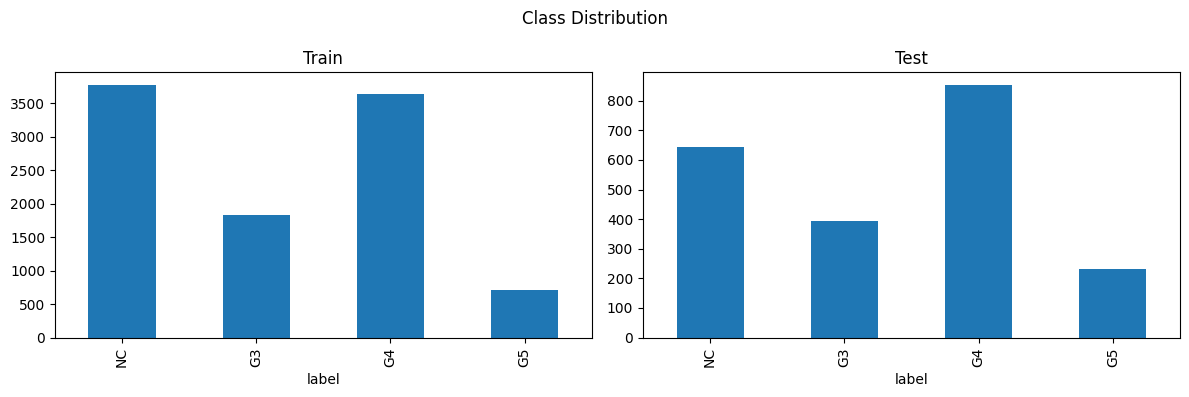

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_train['label'].value_counts().reindex(['NC','G3','G4','G5']).plot(kind='bar', ax=axes[0], title='Train')
df_test['label'].value_counts().reindex(['NC','G3','G4','G5']).plot(kind='bar', ax=axes[1], title='Test')

plt.suptitle('Class Distribution')
plt.tight_layout()
plt.show()

### 2.5 Visual Sample Per Class

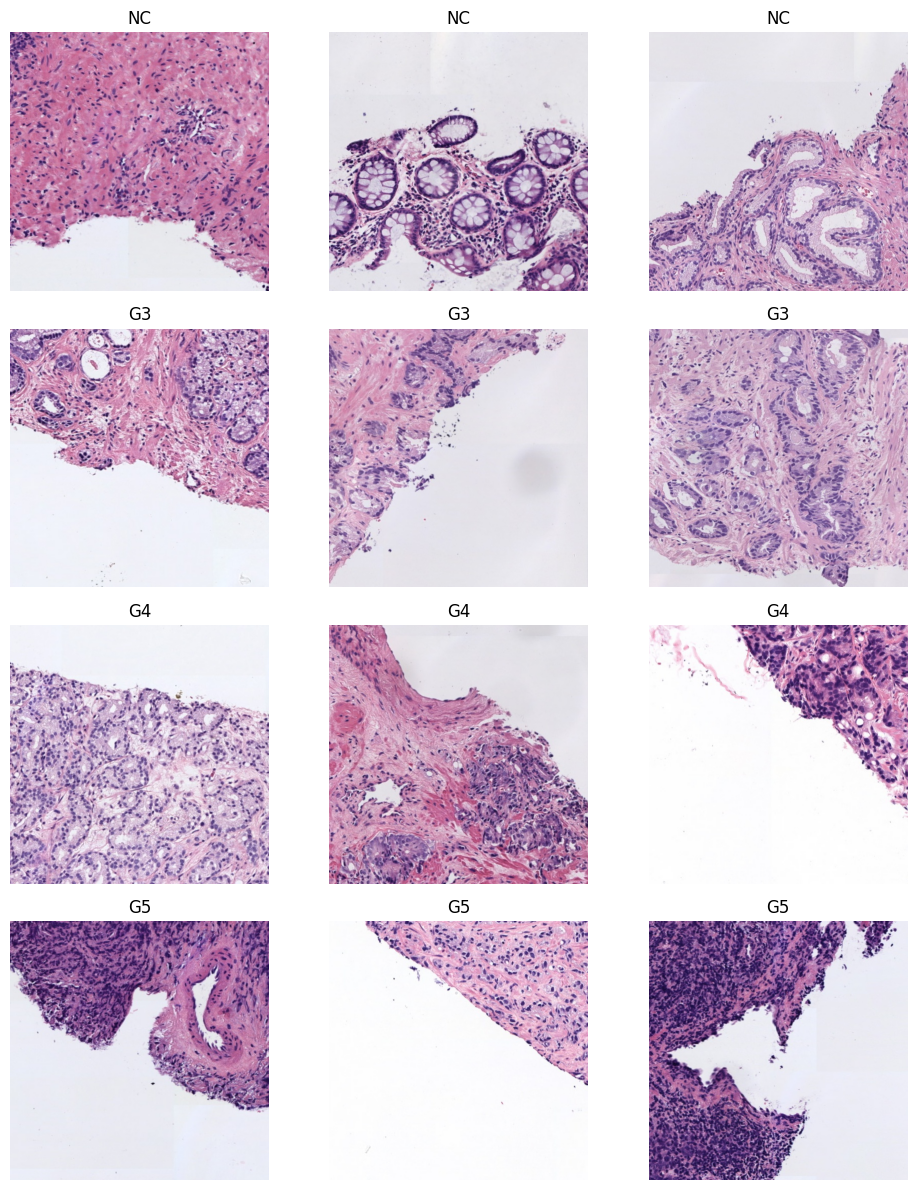

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
classes = ['NC', 'G3', 'G4', 'G5']

for row_idx, cls in enumerate(classes):
    subset = df_train[df_train['label'] == cls].sample(3, random_state=42)
    for col_idx, (_, img_row) in enumerate(subset.iterrows()):
        img_path = f"{BASE}/images/{img_row['image_name']}"
        img = mpimg.imread(img_path)
        axes[row_idx][col_idx].imshow(img)
        axes[row_idx][col_idx].set_title(cls)
        axes[row_idx][col_idx].axis('off')

plt.tight_layout()
plt.show()

### 2.6 Confirming image dimension

**Purpose**

Both backbones (ShuffleNet and MobileNet) expect 224x224 inputs. If the raw images are a different size, the pipeline breaks. This cell opens one sample to check the original dimensions and whether the images are RGB. It also tells us which direction we're resizing, downscale or upscale. Downscaling loses some detail but doesn't invent anything. Upscaling would. The images are 512x512 RGB, so we're downscaling to 224x224 in the pipeline.

In [13]:
from PIL import Image

sample = df_train['image_name'].iloc[0]
img = Image.open(f"{BASE}/images/{sample}")
print(img.size)   # (width, height)
print(img.mode)   # RGB, RGBA, etc.

(512, 512)
RGB


## Section 3: Patient-Disjoint Split

### 3.1 Split Training Patients into Train / Val (seed 42)

**Purpose**

We have 124 training patients. We need to carve out a small validation sample from the training sets, while ensuring split patient disjoint, meaning, no patients appears in both train and val. Therefore we'll do a 80/20 split on patients, not on images. So, roughly 99patients go to train, 25 go to val

In [14]:
train_patients = df_train['patient_id'].unique()

patients_train, patients_val = train_test_split(
    train_patients,
    test_size = .2,
    random_state=42
)

df_tr = df_train[df_train['patient_id'].isin(patients_train)].reset_index(drop=True)
df_val = df_train[df_train['patient_id'].isin(patients_val)].reset_index(drop=True)

print("Train patients:", len(patients_train), "| Images:", len(df_tr))
print("Val patients:", len(patients_val), "| Images:", len(df_val))


Train patients: 99 | Images: 8146
Val patients: 25 | Images: 1813


### 3.2 Save Manifests to Drive

In [15]:
df_tr.to_csv(f'{BASE}/partition/manifest_train.csv', index=False)
df_val.to_csv(f'{BASE}/partition/manifest_val.csv', index=False)

print("Saved manifest_train.csv:", len(df_tr), "images")
print("Saved manifest_val.csv:", len(df_val), "images")

Saved manifest_train.csv: 8146 images
Saved manifest_val.csv: 1813 images


### 3.3 Verify Split Integrity

In [16]:
overlap_tr_val = set(df_tr['patient_id']) & set(df_val['patient_id'])
overlap_val_test = set(df_val['patient_id']) & set(df_test['patient_id'])

print("Train/Val overlap:", len(overlap_tr_val))
print("Val/Test overlap:", len(overlap_val_test))

Train/Val overlap: 0
Val/Test overlap: 0


### 3.4 Patch & Class Counts Per Split

In [17]:
for name,df in [('Train', df_tr), ('Val', df_val), ('Test', df_test)]:
  print(f"{name}: {len(df)} images | {df['patient_id'].nunique()} patients")
  print(df['label'].value_counts().reindex(['NC','G3','G4','G5']))
  print()

Train: 8146 images | 99 patients
label
NC    3099
G3    1506
G4    2976
G5     565
Name: count, dtype: int64

Val: 1813 images | 25 patients
label
NC    674
G3    323
G4    665
G5    151
Name: count, dtype: int64

Test: 2122 images | 31 patients
label
NC    644
G3    393
G4    853
G5    232
Name: count, dtype: int64



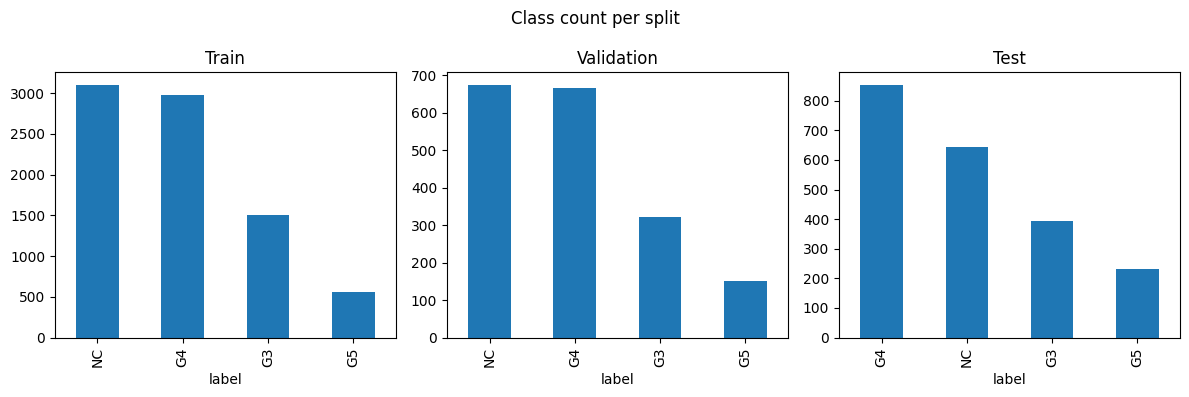

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12,4))

df_tr['label'].value_counts().plot(kind='bar', ax=axes[0], title='Train')
df_val['label'].value_counts().plot(kind='bar', ax=axes[1], title='Validation')
df_test['label'].value_counts().plot(kind='bar', ax=axes[2], title='Test')

plt.suptitle('Class count per split')
plt.tight_layout()
plt.show()

## Section 4: tf.data Pipeline

**Purpose**

The pipeline has to go from a CSV row (a filename and a label) to a batch of tensors the model can train on. That involves reading the file, resizing it, optionally degrading it, and optionally augmenting it. Sections 4.1 and 4.2 build the two pieces that handle this: the degradation functions and the prepare() function that ties everything together. Section 4.3 wraps them into a full tf.data pipeline.

### 4.1 Degradation Augmentation Module

In [24]:
# When transferring images over slow and unstable networks, JPEF is the most common format for transmitting because it dramatically reduces file size, allowing for faster transmission. This fuction simulates this JPEG compression

def apply_jpeg_compression(image,quality):
  ### TF images are float32 [0,1] but JPEG encode needs uint8 [0,255] ###

  image_uint8 = tf.cast(image * 255.0, tf.uint8)
  # image * 255.0 converts from 0-1 range to 0-255 range
  # tf.cast(..., tf.uint8) converts them from float to an 8bit integer

  ### Simulate jpeg compression ###

  # Encoding compresses and loses information
  encoded = tf.image.encode_jpeg(image_uint8, quality=quality)
  # Decode reconstructs from the information that is left
  decoded = tf.image.decode_jpeg(encoded, channels=3)

  ### Conver back to float32[0,1] for the model ###
  return tf.cast(decoded, tf.float32) / 255.0

# To reduce file size and transmision time over slow or unstable network, the image get scale down before sending. This function is how we simulate this image downsampling
def apply_downsampling(image, factor):
  #### get current dimensions ####
  h = tf.shape(image)[0]
  w = tf.shape(image)[1]

  # Shrink by factor (e.g 0.5 = half size)
  small_h = tf.cast(tf.cast(h, tf.float32) * factor, tf.int32)
  small_w = tf.cast(tf.cast(w, tf.float32)* factor, tf.int32)
  small = tf.image.resize(image, [small_h, small_w])

  # scale back up: Scaling back up introduces blur, simulating low-res transmission
  return tf.image.resize(small, [h,w])

def apply_degradation(image,jpeg_quality=None,downsample_factor=None):
  # apply compresssion if quality specified
  if jpeg_quality is not None:
    image = apply_jpeg_compression(image, jpeg_quality)

  # apply downsampling if downsampling factor specified
  if downsample_factor is not None:
    image = apply_downsampling(image,downsample_factor)

  # if both are none the images passes through untouched

  return image

### 4.2 prepare() Function

**Purpose**

`prepare()` is called once per image, every time that image is pulled from the dataset during training or evaluation.

It sits between the raw data (a filename in a CSV) and the model (which needs a float32 tensor of shape (224, 224, 3)). Every image has to pass through it before the model ever sees it.

In [42]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

def prepare(image_path, label, augment=False, jpeg_quality=None, downsample_factor=None):
  image = tf.io.read_file(image_path)
  # tf.io.read_file reads the raw bytes of the image from the disk

  image = tf.image.decode_jpeg(image, channels=3)
  # tf.image.decode_jpeg converts those bytes into a pixel tensor of dimension (512,512,3)

  # convert to float32 [0,1]
  image = tf.cast(image, tf.float32) / 255.0

  # resize image to match model size
  image = tf.image.resize(image, [224,224])

  # apply degradation if specified
  image = apply_degradation(image, jpeg_quality=jpeg_quality, downsample_factor=downsample_factor)

  # apply augmentation only during training

  if augment:
    image = augmentation(image, training=True)

  return image, label


### 4.3 build_dataset() Function

In [43]:
def build_dataset(df, augment=False, jpeg_quality=None, downsample_factor=None, batch_size=32, shuffle=False):
    # build full image paths from filenames
    image_paths = [f"{BASE}/images/{fname}" for fname in df['image_name']]

    # convert string labels to integers
    label_map = {'NC': 0, 'G3': 1, 'G4': 2, 'G5': 3}
    labels = [label_map[l] for l in df['label']]

    # create dataset from paths and labels
    ds = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    # shuffle before mapping -- only for training
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)

    # apply prepare() to every (path, label) pair
    ds = ds.map(
        lambda path, label: prepare(path, label, augment=augment, jpeg_quality=jpeg_quality, downsample_factor=downsample_factor),
        num_parallel_calls=AUTOTUNE
    )

    return ds.batch(batch_size).prefetch(AUTOTUNE)

### 4.4 Build train_ds, val_ds, test_ds

In [44]:

# Training dataset:
#   augment=True: applies the random flips, rotations, zoom applied
#   shuffle=True: the images drawn in random order each epoch
#   No fixed degradation here, during training we want the model
#   to see clean images so it learns features, not compression noise.
#   Degradation-aware training ( later) would pass jpeg_quality and downsampling here

train_ds = build_dataset(
    df_tr,
    augment = True,
    shuffle = True,
    batch_size=32
)

# Validation dataset:
#   augment=False: no random transforms; we want a stable, repeatable score
#   shuffle=False: order doesn't matter for evaluation
#   No degradation: val measures model quality on clean images
val_ds = build_dataset(
    df_val,
    augment=False,
    shuffle=False,
    batch_size=32
)

# Test dataset:
#   Same clean settings as val, degradation is added later in Section 7
#   when we evaluate each of the 7 compression/resolution conditions.
#   We never touch test_ds here; it stays clean until final evaluation.
test_ds = build_dataset(
    df_test,
    augment=False,
    shuffle=False,
    batch_size=32
)


In [45]:
# Quick sanity check: print the shape of one batch from each split
for name, ds in [('Train', train_ds), ('Val', val_ds), ('Test', test_ds)]:
    images, labels = next(iter(ds))
    print(f"{name} — images: {images.shape}, labels: {labels.shape}")

Train — images: (32, 224, 224, 3), labels: (32,)
Val — images: (32, 224, 224, 3), labels: (32,)
Test — images: (32, 224, 224, 3), labels: (32,)


## Section 5: Model Definitions

### 5.1 MobileNetV3 Small Builder

In [46]:
def build_mobilenetv3(num_classes=4, input_shape=(224,224,3), dropout=0.3):
  base = keras.applications.MobileNetV3Small(
      input_shape=input_shape,
      include_top=False,
      weights='imagenet'
  )

  base.trainable= False

  return tf.keras.Sequential([
      base,
      layers.GlobalAveragePooling2D(),
      layers.Dense(256, activation='relu'),
      layers.Dropout(dropout),
      layers.Dense(num_classes, activation='softmax')
  ], name='mobilenetv3_small')

### 5.2 ShuffleNetV2 Builder

In [ ]:

def channel_shuffle(x, groups=2):
    """Reshape -> transpose -> reshape to mix channels across groups."""
    batch = tf.shape(x)[0]
    h     = tf.shape(x)[1]
    w     = tf.shape(x)[2]
    c     = x.shape[-1]   # static channel dim

    x = tf.reshape(x, [batch, h, w, groups, c // groups])
    x = tf.transpose(x, [0, 1, 2, 4, 3])
    x = tf.reshape(x, [batch, h, w, c])
    return x


def conv_bn_relu(filters, kernel_size, stride=1, groups=1):
    """Sequential block: Conv -> BN -> ReLU. Reused across both branches."""
    return tf.keras.Sequential([
        layers.Conv2D(filters, kernel_size, strides=stride,
                      padding='same', groups=groups, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU()
    ])


def dwconv_bn(kernel_size=3, stride=1):
    """Sequential block: DepthwiseConv -> BN (no activation -- ReLU follows the next conv)."""
    return tf.keras.Sequential([
        layers.DepthwiseConv2D(kernel_size, strides=stride,
                               padding='same', use_bias=False),
        layers.BatchNormalization()
    ])


def shuffle_unit_stride1(x, out_channels):
    """
    Stride-1 block.
    Left:  identity (first half of channels).
    Right: 1x1 conv -> DWConv 3x3 -> 1x1 conv (second half).
    Concat + channel shuffle.
    """
    c = out_channels // 2

    x_left  = x[:, :, :, :c]
    x_right = x[:, :, :, c:]

    x_right = conv_bn_relu(c, 1)(x_right)
    x_right = dwconv_bn(3, stride=1)(x_right)
    x_right = conv_bn_relu(c, 1)(x_right)

    return channel_shuffle(tf.concat([x_left, x_right], axis=-1))


def shuffle_unit_stride2(x, out_channels):
    """
    Stride-2 block (spatial downsampling, no channel split).
    Left:  DWConv 3x3 stride-2 -> 1x1 conv.
    Right: 1x1 conv -> DWConv 3x3 stride-2 -> 1x1 conv.
    Concat + channel shuffle.
    """
    c = out_channels // 2

    x_left = dwconv_bn(3, stride=2)(x)
    x_left = conv_bn_relu(c, 1)(x_left)

    x_right = conv_bn_relu(c, 1)(x)
    x_right = dwconv_bn(3, stride=2)(x_right)
    x_right = conv_bn_relu(c, 1)(x_right)

    return channel_shuffle(tf.concat([x_left, x_right], axis=-1))


def build_shufflenetv2(num_classes=4, input_shape=(224, 224, 3), dropout=0.3):
    """
    ShuffleNet V2 1.0x.
    Stage channels: [116, 232, 464] -> final conv 1024 -> GAP -> head.
    """
    stage_channels = [116, 232, 464]
    stage_repeats  = [3, 7, 3]

    inputs = tf.keras.Input(shape=input_shape)

    # Stem
    x = conv_bn_relu(24, 3, stride=2)(inputs)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding='same')(x)

    # Stages
    for out_ch, repeats in zip(stage_channels, stage_repeats):
        x = shuffle_unit_stride2(x, out_ch)
        for _ in range(repeats):
            x = shuffle_unit_stride1(x, out_ch)

    # Final conv + head
    x = conv_bn_relu(1024, 1)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs, outputs, name='shufflenetv2_1x')

## Section 6: Training

### 6.1 Run 1 — MobileNetV3 Clean

### 6.2 Run 2 — MobileNetV3 Degradation-Aware

### 6.3 Run 3 — ShuffleNetV2 Clean

### 6.4 Run 4 — ShuffleNetV2 Degradation-Aware

## Section 7: Evaluation

### 7.1 Load Saved Models

### 7.2 Run Inference Under All 7 Test Conditions

### 7.3 Collect Metrics Per (Model, Condition)

### 7.4 Build 28-Row Results Table

### 7.5 Save Results to Drive

## Section 8: Analysis

### 8.1 Macro F1 Comparison

### 8.2 Per-Class Recall Breakdown

### 8.3 Uncertainty vs Degradation Level

### 8.4 Accuracy vs File Size Trade-off